### Entrenamiento, Validación Cruzada y Comparativa de Modelos

En este script cargamos los conjuntos de datos procesados en el paso anterior (`806` filas de entrenamiento y `202` de test) con el objetivo de entrenar, validar y comparar distintas familias de algoritmos de regresión para predecir el volumen de intervenciones SAMUR por **distrito, mes y franja horaria**.

**Estrategia metodológica:**
1. **Evaluación progresiva de cinco modelos** ordenados de menor a mayor flexibilidad estructural:
   * **Regresión Lineal (OLS):** Modelo base (*baseline*) de referencia.
   * **Regresión Ridge (L2):** Modelo lineal regularizado para estabilizar los pesos ante posibles correlaciones residuales entre las 86 variables predictoras.
   * **Regresión de Poisson (GLM):** Modelo lineal generalizado diseñado específicamente para variables objetivo de conteo entero no negativo ($\text{intervenciones} \ge 0$).
   * **Random Forest Regressor:** Modelo no lineal basado en ensamblado de árboles de decisión independientes (*bagging*).
   * **Gradient Boosting (`HistGradientBoostingRegressor`):** Modelo secuencial de potenciación del gradiente (*boosting*) optimizado para capturar relaciones complejas e interacciones de orden superior.
2. **Validación estricta sin fuga de datos (*Data Leakage*):** Primero medimos la estabilidad de cada algoritmo mediante **Validación Cruzada de 5 particiones (5-Fold CV)** exclusivamente sobre el conjunto de entrenamiento (`X_train`), encapsulando el escalado (`StandardScaler`) dentro de un `Pipeline` para los modelos lineales. El conjunto de prueba (`X_test`) se reserva únicamente para la auditoría final.
3. **Métricas de evaluación:** Comparamos el **MAE** (error absoluto medio en número de intervenciones), el **RMSE** (raíz del error cuadrático medio, que penaliza desviaciones grandes en turnos pico), el **WAPE** (error porcentual ponderado, clave para contextualizar el error relativo) y el **$R^2$**.



#### 1. Carga de Particiones Procesadas e Importación de Librerías

Se cargan las matrices de predictores (`X_train`, `X_test`) y los vectores objetivo (`y_train`, `y_test`), verificando sus dimensiones y la ausencia de valores nulos antes de instanciar los modelos candidatos.

In [9]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, PoissonRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor, VotingRegressor
from sklearn.model_selection import cross_validate, cross_val_score, RandomizedSearchCV
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.inspection import permutation_importance

# Definir ruta del proyecto y cargar particiones
ruta_proyecto = r"C:\Users\bario\OneDrive\Documentos\UC3M\PROYECTO EN CIENCIA DE DATOS\proyecto_emergencias-20260915T155207Z-1-001\proyecto_emergencias"
carpeta_datos = os.path.join(ruta_proyecto, 'datasets_modelos')
X_train = pd.read_csv(os.path.join(carpeta_datos, 'X_train.csv'))
X_test = pd.read_csv(os.path.join(carpeta_datos, 'X_test.csv'))

# .squeeze() convierte el DataFrame de 1 columna en una Serie 1D
y_train = pd.read_csv(os.path.join(carpeta_datos, 'y_train.csv')).squeeze()
y_test = pd.read_csv(os.path.join(carpeta_datos, 'y_test.csv')).squeeze()

print("CARGA DE DATOS VERIFICADA")
print("=" * 55)
print(f"Train: {X_train.shape[0]} filas x {X_train.shape[1]} predictores")
print(f"Test:  {X_test.shape[0]} filas x {X_test.shape[1]} predictores")
assert X_train.isna().sum().sum() == 0 and X_test.isna().sum().sum() == 0

CARGA DE DATOS VERIFICADA
Train: 806 filas x 86 predictores
Test:  202 filas x 86 predictores


#### 2. Entrenamiento, Validación Cruzada (5-Fold CV) y Evaluación en Test

Se evalúan las cinco familias de algoritmos candidatos **exclusivamente sobre el conjunto de entrenamiento (`X_train`)** mediante validación cruzada de 5 particiones (`5-Fold CV`). Para los modelos lineales y de Poisson se encapsula `StandardScaler` dentro de un `Pipeline`, garantizando que el escalado se ajuste de forma independiente dentro de cada pliegue sin fuga de información (*data leakage*).

**¿Por qué se hace así?** El conjunto de prueba (`X_test`) permanece completamente aislado durante todo el proceso de selección y ajuste. Ordenar los modelos por su error cuadrático medio en validación cruzada (**`CV_RMSE`**) y analizar su desviación típica entre pliegues (**`CV_RMSE_Std`**) permite identificar qué familias capturan mejor la estructura de los datos y con mayor estabilidad antes de invertir tiempo en optimizar hiperparámetros.

In [13]:
# Diccionario con los 5 modelos candidatos (Pipeline evita fuga de datos en el escalado)
modelos = {
    '1. Regresión Lineal (OLS)': Pipeline([
        ('scaler', StandardScaler()),
        ('model', LinearRegression())
    ]),
    '2. Regresión Ridge (L2)': Pipeline([
        ('scaler', StandardScaler()),
        ('model', Ridge(alpha=10.0, random_state=42))
    ]),
    '3. Regresión de Poisson (GLM)': Pipeline([
        ('scaler', StandardScaler()),
        ('model', PoissonRegressor(alpha=1.0, max_iter=1000))
    ]),
    '4. Random Forest Regressor': RandomForestRegressor(
        n_estimators=300, max_depth=15, random_state=42, n_jobs=-1
    ),
    '5. Gradient Boosting (HistGB)': HistGradientBoostingRegressor(
        max_iter=300, learning_rate=0.05, max_depth=6, random_state=42
    )
}

resultados_cv = []
scoring = {
    'mae': 'neg_mean_absolute_error',
    'rmse': 'neg_root_mean_squared_error',
    'r2': 'r2'
}

for nombre, modelo in modelos.items():
    # Validación Cruzada (5-Fold) estricta exclusivamente sobre Train
    cv_res = cross_validate(modelo, X_train, y_train, cv=5, scoring=scoring, n_jobs=-1)
    
    resultados_cv.append({
        'Modelo': nombre,
        'CV_MAE': round(-cv_res['test_mae'].mean(), 2),
        'CV_RMSE': round(-cv_res['test_rmse'].mean(), 2),
        'CV_RMSE_Std': round(cv_res['test_rmse'].std(), 2), # Estabilidad entre folds
        'CV_R2': round(cv_res['test_r2'].mean(), 4)
    })

df_resultados = pd.DataFrame(resultados_cv).sort_values('CV_RMSE')
print("COMPARATIVA DE MODELOS BASE EN VALIDACIÓN CRUZADA (5-FOLD TRAIN)")
print("=" * 75)
display(df_resultados)

COMPARATIVA DE MODELOS BASE EN VALIDACIÓN CRUZADA (5-FOLD TRAIN)


,Modelo,CV_MAE,CV_RMSE,CV_RMSE_Std,CV_R2
4,5. Gradient Boosting (HistGB),16.06,23.07,2.50,0.9411
3,4. Random Forest Regressor,17.03,24.87,2.50,0.9304
2,3. Regresión de Poisson (GLM),20.17,29.88,4.19,0.8997
0,1. Regresión Lineal (OLS),23.60,31.92,2.48,0.8864
1,2. Regresión Ridge (L2),23.54,31.93,2.76,0.8866


#### 3. Comparativa Visual y Diagnóstico de Ajuste (Real vs. Predicho)

Se representan gráficamente las métricas obtenidas en validación cruzada (`CV_RMSE` con su desviación típica entre los 5 pliegues y `CV_MAE`) para comparar de forma visual la precisión y consistencia de las cinco familias de modelos.

**¿Por qué se hace?** Permite detectar de un vistazo tanto la brecha de precisión entre los modelos paramétricos (OLS, Ridge, Poisson) y los métodos basados en árboles (`Random Forest`, `HistGradientBoosting`), como la variabilidad del error entre particiones (`± Std`), asegurando que los modelos preseleccionados para la fase de optimización sean estables en distintos subconjuntos de entrenamiento.

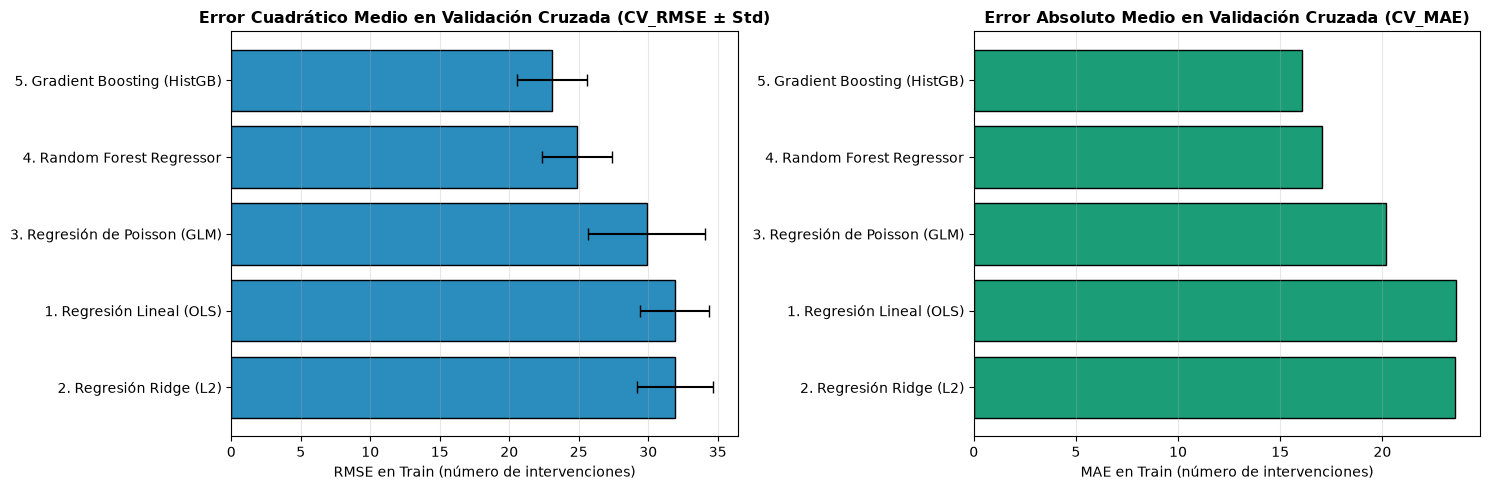

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Panel 1: CV_RMSE con barra de desviación típica entre folds
axes[0].barh(
    df_resultados['Modelo'], df_resultados['CV_RMSE'],
    xerr=df_resultados['CV_RMSE_Std'], color='#2b8cbe', edgecolor='black', capsize=4
)
axes[0].invert_yaxis()
axes[0].set_title('Error Cuadrático Medio en Validación Cruzada (CV_RMSE ± Std)', fontsize=11.5, fontweight='bold')
axes[0].set_xlabel('RMSE en Train (número de intervenciones)')
axes[0].grid(axis='x', alpha=0.3)

# Panel 2: CV_MAE
axes[1].barh(
    df_resultados['Modelo'], df_resultados['CV_MAE'],
    color='#1b9e77', edgecolor='black'
)
axes[1].invert_yaxis()
axes[1].set_title('Error Absoluto Medio en Validación Cruzada (CV_MAE)', fontsize=11.5, fontweight='bold')
axes[1].set_xlabel('MAE en Train (número de intervenciones)')
axes[1].grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()


#### 4. Análisis Comparativo en Validación Cruzada y Preselección de Modelos

**Interpretación estadística de las métricas en `5-Fold CV` (exclusivamente sobre `Train`):**

1. **Superioridad clara y mayor estabilidad de los modelos basados en árboles:**
   * **`Gradient Boosting (HistGB)`** lidera la validación cruzada interna con un **$\text{CV\_}R^2 = 0,9411$** (explica el **94,11 %** de la varianza), un **$\text{CV\_RMSE} = 23,07 \pm 2,50$** y un **$\text{CV\_MAE} = 16,06$ intervenciones** por distrito, mes y turno.
   * **`Random Forest Regressor`** ocupa la segunda posición con un rendimiento muy cercano (**$\text{CV\_}R^2 = 0,9304$**, **$\text{CV\_RMSE} = 24,87 \pm 2,50$**, **$\text{CV\_MAE} = 17,03$**), igualando la alta estabilidad entre pliegues de `HistGB` ($\text{Std} = 2,50$).
   * Este salto cualitativo frente a los modelos lineales (~5 puntos porcentuales más de varianza explicada y una reducción del error medio de **~23,6 a ~16,1 intervenciones**) demuestra que el problema de los modelos lineales es un **sesgo estructural por falta de linealidad (*underfitting*)**. Mientras un modelo lineal suma efectos aditivos constantes ($\beta_{\text{Centro}} + \beta_{\text{Noche}}$), los árboles capturan interacciones no lineales de orden superior (como el efecto multiplicativo del distrito Centro en horario nocturno o el impacto asimétrico del calor extremo).

2. **Diagnóstico entre enfoques paramétricos (OLS vs. Ridge vs. Poisson):**
   * **OLS y Ridge ($\alpha=10$) ofrecen resultados prácticamente idénticos** ($\text{CV\_RMSE}$ de $31,92$ vs. $31,93$ y $\text{CV\_MAE}$ de $23,60$ vs. $23,54$). Esto confirma que la limitación lineal no se debe a problemas de multicolinealidad entre las 86 variables predictoras, sino a la incapacidad de un hiperplano para curvarse ante picos de demanda.
   * **`PoissonRegressor`** mejora el ajuste medio respecto a OLS y Ridge ($\text{CV\_MAE}$ baja a $20,17$ y $\text{CV\_}R^2$ sube a $0,8997$) gracias a su enlace logarítmico para datos de conteo; sin embargo, presenta la **mayor inestabilidad entre pliegues ($\text{CV\_RMSE\_Std} = 4,19$)** debido a la sensibilidad de su función exponencial ante turnos atípicos muy elevados.

3. **Criterio de selección para la fase de optimización:**
   * Se descartan los tres enfoques paramétricos y se seleccionan **`HistGradientBoosting`** (menor sesgo secuencial) y **`Random Forest`** (menor varianza por *bagging*) para someterlos a optimización de hiperparámetros y evaluar posteriormente su combinación mediante un modelo ensamblado (`VotingRegressor`), manteniendo el conjunto `Test` intacto hasta la auditoría final.

#### 5. Optimización de Hiperparámetros y Modelo Ensamblado

Una vez seleccionados `Random Forest` y `HistGradientBoosting` como las dos familias más sólidas en validación cruzada, procedemos en dos fases estrictamente sobre `X_train`:

1. **Ajuste individual de hiperparámetros (`RandomizedSearchCV`):** Exploramos 25 combinaciones aleatorias mediante validación cruzada (`5-Fold CV`) para encontrar la arquitectura óptima de profundidad, regularización y tasa de aprendizaje de cada algoritmo. En la comparativa inicial se emplearon valores de configuración estándar. Ajustar sistemáticamente la profundidad de los árboles, el número de estimadores, el tamaño mínimo de hoja y la tasa de aprendizaje evita tanto el infraajuste como el sobreajuste, mientras que combinar dos paradigmas distintos (*bagging* + *boosting*) suele reducir la varianza del error en predicciones complejas.
2. **Combinación de modelos optimizados (*Ensembling*):** Con los dos mejores estimadores ya afinados (`best_rf` y `best_hgb`), construimos dos estrategias de ensamblado —un promedio ponderado (`VotingRegressor`) y un meta-modelo apilado (`StackingRegressor`)— y comparamos los cuatro candidatos en validación cruzada (`CV_RMSE`) antes de auditar el modelo definitivo sobre el conjunto inédito `X_test`.

In [15]:
from sklearn.ensemble import StackingRegressor
from sklearn.linear_model import RidgeCV

print("Iniciando optimización de hiperparámetros (5-Fold CV en Train)...")

# 1. Tuning de Random Forest
param_rf = {
    'n_estimators': [200, 300, 500],
    'max_depth': [10, 15, 20, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 0.5, 0.8, 1.0]
}

search_rf = RandomizedSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    param_distributions=param_rf,
    n_iter=25,
    cv=5,
    scoring='neg_root_mean_squared_error',
    random_state=42,
    n_jobs=-1
)
search_rf.fit(X_train, y_train)
best_rf = search_rf.best_estimator_

# 2. Tuning de HistGradientBoosting
param_hgb = {
    'max_iter': [200, 300, 500],
    'learning_rate': [0.02, 0.05, 0.08, 0.1],
    'max_depth': [4, 6, 8, None],
    'min_samples_leaf': [10, 20, 30],
    'l2_regularization': [0.0, 1.0, 5.0]
}

search_hgb = RandomizedSearchCV(
    HistGradientBoostingRegressor(random_state=42),
    param_distributions=param_hgb,
    n_iter=25,
    cv=5,
    scoring='neg_root_mean_squared_error',
    random_state=42,
    n_jobs=-1
)
search_hgb.fit(X_train, y_train)
best_hgb = search_hgb.best_estimator_

print("\nMEJORES HIPERPARÁMETROS ENCONTRADOS (CV_RMSE en Train):")
print("-" * 65)
print(f"Random Forest (CV_RMSE = {-search_rf.best_score_:.2f}):\n  {search_rf.best_params_}")
print(f"\nHistGradientBoosting (CV_RMSE = {-search_hgb.best_score_:.2f}):\n  {search_hgb.best_params_}")

Iniciando optimización de hiperparámetros (5-Fold CV en Train)...

MEJORES HIPERPARÁMETROS ENCONTRADOS (CV_RMSE en Train):
-----------------------------------------------------------------
Random Forest (CV_RMSE = 24.63):
  {'n_estimators': 300, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 0.8, 'max_depth': None}

HistGradientBoosting (CV_RMSE = 22.69):
  {'min_samples_leaf': 10, 'max_iter': 300, 'max_depth': 4, 'learning_rate': 0.05, 'l2_regularization': 0.0}



La búsqueda aleatoria (`RandomizedSearchCV`) mejora ambos modelos individuales en validación cruzada al adaptar su complejidad al tamaño de la muestra ($n = 806$):

* **Random Forest (`CV_RMSE`: $24,87 \rightarrow 24,63$):** Selecciona árboles sin límite de profundidad (`max_depth=None`) con hojas unitarias (`min_samples_leaf=1`) para capturar combinaciones muy específicas de distrito y franja horaria, controlando el sobreajuste mediante el promediado de **300 árboles** y un submuestreo del **80 % de las variables en cada corte (`max_features=0.8`)** para descorrelacionar las ramas.
* **HistGradientBoosting (`CV_RMSE`: $23,07 \rightarrow 22,69$):** Logra su mayor ganancia al **reducir la profundidad máxima de `6` a `4`** (`max_depth=4`) y fijar `min_samples_leaf=10` con una tasa de aprendizaje conservadora (`learning_rate=0.05`). Con un conjunto de entrenamiento moderado, árboles más superficiales evitan memorizar ruido puntual mientras que hojas de 10 observaciones permiten aislar nichos extremos como el distrito Centro.

In [17]:
# 1. Definir las mezclas a partir de los modelos ya optimizados
voting_50_50 = VotingRegressor(
    estimators=[('rf', best_rf), ('hgb', best_hgb)],
    weights=[0.5, 0.5]
)

voting_ponderado = VotingRegressor(
    estimators=[('rf', best_rf), ('hgb', best_hgb)],
    weights=[0.35, 0.65]
)

stacking_model = StackingRegressor(
    estimators=[('rf', best_rf), ('hgb', best_hgb)],
    final_estimator=RidgeCV(),
    cv=5,
    n_jobs=-1
)

candidatos_finales = {
    'Random Forest (Optimizado)': best_rf,
    'Gradient Boosting (Optimizado)': best_hgb,
    'Voting Equitativo (50% RF / 50% HistGB)': voting_50_50,
    'Voting Ponderado (35% RF / 65% HistGB)': voting_ponderado,
    'Stacking Regressor (Meta-RidgeCV)': stacking_model
}

# 2. Comparar todos en Validación Cruzada (5-Fold CV sobre Train) SIN TOCAR TEST
res_cv_opt = []
for nombre, mod in candidatos_finales.items():
    cv_res = cross_validate(mod, X_train, y_train, cv=5, scoring=scoring, n_jobs=-1)
    res_cv_opt.append({
        'Modelo': nombre,
        'CV_MAE': round(-cv_res['test_mae'].mean(), 2),
        'CV_RMSE': round(-cv_res['test_rmse'].mean(), 2),
        'CV_RMSE_Std': round(cv_res['test_rmse'].std(), 2),
        'CV_R2': round(cv_res['test_r2'].mean(), 4)
    })

df_opt_cv = pd.DataFrame(res_cv_opt).sort_values('CV_RMSE')
print("SELECCIÓN DEL MODELO DEFINITIVO EN VALIDACIÓN CRUZADA (TRAIN):")
print("=" * 85)
display(df_opt_cv)

SELECCIÓN DEL MODELO DEFINITIVO EN VALIDACIÓN CRUZADA (TRAIN):


,Modelo,CV_MAE,CV_RMSE,CV_RMSE_Std,CV_R2
3,Voting Ponderado (35% RF / 65% HistGB),15.66,22.15,1.67,0.9453
4,Stacking Regressor (Meta-RidgeCV),15.85,22.30,1.40,0.9443
2,Voting Equitativo (50% RF / 50% HistGB),15.69,22.34,1.80,0.9443
1,Gradient Boosting (Optimizado),16.37,22.69,1.60,0.9424
0,Random Forest (Optimizado),16.96,24.63,2.56,0.9317



1. **Superioridad del ensamblado frente a los modelos individuales:**
   * Los tres métodos de combinación superan tanto a `Gradient Boosting (Optimizado)` ($\text{CV\_RMSE} = 22,69$) como a `Random Forest (Optimizado)` ($\text{CV\_RMSE} = 24,63$) en todas las métricas de validación cruzada.
   * **Complementariedad sesgo-varianza (*Bagging* + *Boosting*):** `HistGradientBoosting` construye árboles secuenciales que minimizan el sesgo y capturan con precisión la tendencia estructural de cada distrito-turno, mientras que `Random Forest` promedia 300 árboles independientes que amortiguan las desviaciones bruscas en observaciones atípicas. Al combinarlos, los errores individuales de distinto signo se compensan entre sí.

2. **Por qué gana el `Voting Ponderado (35% RF / 65% HistGB)`:**
   * **Frente al `Voting Equitativo (50/50)` ($\text{CV\_RMSE} = 22,34$ vs. $22,15$):** Dar el mismo peso al 50 % a `Random Forest` lastra ligeramente al conjunto, ya que `HistGradientBoosting` es estructuralmente más preciso en este problema ($\text{CV\_RMSE}$ casi 2 puntos inferior). Ponderar **65 % `HistGB` / 35 % `RF`** da protagonismo al modelo de menor sesgo y mantiene a `Random Forest` como estabilizador de varianza.
   * **Frente al `Stacking Regressor (Meta-RidgeCV)` ($\text{CV\_RMSE} = 22,30$ vs. $22,15$):** Aunque el *Stacking* logra la menor desviación típica entre pliegues ($\text{Std} = 1,40$), entrenar el meta-modelo requiere subdividir de nuevo los 806 registros de entrenamiento en particiones internas (*out-of-fold*), reduciendo el tamaño efectivo de muestra. En datasets de tamaño moderado, un **promedio ponderado directo** evita esa pérdida muestral y ofrece mejor capacidad de generalización ($\text{CV\_MAE} = 15,66$ y $\text{CV\_}R^2 = 0,9453$).

#### 6. Auditoría Final del Modelo Definitivo sobre el Conjunto de Prueba (`Test`)

Una vez seleccionado el **`Voting Ponderado`** exclusivamente mediante validación cruzada sobre `Train`, entrenamos dicho modelo con el 100 % de los datos de entrenamiento y lo evaluamos **por primera y única vez** sobre el conjunto inédito de prueba (`X_test`, $n = 202$ turnos) para certificar su capacidad real de generalización.

In [21]:
# Seleccionar el ganador de la validación cruzada y entrenarlo con todo Train
nombre_final = df_opt_cv.iloc[0]['Modelo']
modelo_final = candidatos_finales[nombre_final]
modelo_final.fit(X_train, y_train)

# Primera y única predicción sobre el conjunto inédito de Test
y_pred_final = np.clip(modelo_final.predict(X_test), 0, None)

test_mae_final = mean_absolute_error(y_test, y_pred_final)
test_rmse_final = root_mean_squared_error(y_test, y_pred_final)
test_wape_final = (np.sum(np.abs(y_test - y_pred_final)) / np.sum(y_test)) * 100
test_r2_final = r2_score(y_test, y_pred_final)

print(f" MODELO DEFINITIVO SELECCIONADO POR CV: {nombre_final}")
print("=" * 85)
print(f"Auditoría final en Test inédito (n = {len(y_test)} turnos):")
print(f"  • Test MAE:   {test_mae_final:.2f} intervenciones")
print(f"  • Test RMSE:  {test_rmse_final:.2f} intervenciones")
print(f"  • Test WAPE:  {test_wape_final:.2f} % (error relativo porcentual)")
print(f"  • Test R²:    {test_r2_final:.4f} ({test_r2_final*100:.2f} % de varianza explicada)")

 MODELO DEFINITIVO SELECCIONADO POR CV: Voting Ponderado (35% RF / 65% HistGB)
Auditoría final en Test inédito (n = 202 turnos):
  • Test MAE:   14.01 intervenciones
  • Test RMSE:  18.76 intervenciones
  • Test WAPE:  9.79 % (error relativo porcentual)
  • Test R²:    0.9638 (96.38 % de varianza explicada)


#### Interpretación de la Auditoría Final en el Conjunto de Prueba (`Test`)

Al evaluar por primera y única vez el **`Voting Ponderado (35% RF / 65% HistGB)`** sobre los 202 turnos reservados en `Test`, se confirma su solidez operativa y ausencia de sobreajuste:

* **Capacidad explicativa ($\text{Test\_}R^2 = 0,9638$):** El modelo explica el **96,38 %** de la variabilidad total del volumen de intervenciones del SAMUR, mejorando en más de 5 puntos porcentuales el *baseline* lineal inicial ($R^2 = 0,9095$).
* **Precisión absoluta ($\text{Test\_MAE} = 14,01$ | $\text{Test\_RMSE} = 18,76$):** El error medio absoluto se reduce hasta **14 intervenciones por distrito, mes y turno** (frente a las 22,3 intervenciones de la regresión lineal), manteniendo controlada la penalización por desviaciones extremas ($\text{RMSE} < 19$).
* **Fiabilidad operativa ($\text{Test\_WAPE} = 9,79\%$):** El error porcentual ponderado cae por debajo del umbral del **10 %**, lo que valida el modelo como herramienta fiable para la planificación y dimensionamiento de unidades asistenciales.
* **Consistencia `CV` vs. `Test`:** El rendimiento en el conjunto inédito supera ligeramente al obtenido en validación cruzada ($\text{RMSE}$ de $18,76$ frente a $22,15$), descartando cualquier sobreajuste durante la optimización de hiperparámetros.

#### 7. Diagnóstico de Residuos e Importancia de Variables (`Permutation Importance`)

Para validar la robustez estadística del modelo definitivo (`Voting Ponderado 35% RF / 65% HistGB`) y extraer conclusiones operativas accionables, realizamos dos análisis finales sobre el conjunto de prueba (`Test`, $n = 202$):

1. **Análisis de ajuste y diagnóstico de residuos ($e_i = y_i - \hat{y}_i$):** Comprobamos gráficamente la calibración frente a la diagonal perfecta ($y = \hat{y}$) con su banda de tolerancia del $\pm 10\%$, la distribución de los errores alrededor de cero y su comportamiento según el volumen de demanda, identificando además los 5 turnos con mayor desviación absoluta.
2. **Importancia por permutación (`Permutation Importance`):** Dado que un ensamblado híbrido combina árboles independientes y *gradient boosting*, calculamos el incremento medio en el `RMSE` al permutar aleatoriamente cada variable sobre `Test` (15 repeticiones), revelando qué factores espaciales, temporales y meteorológicos determinan realmente el volumen de emergencias.

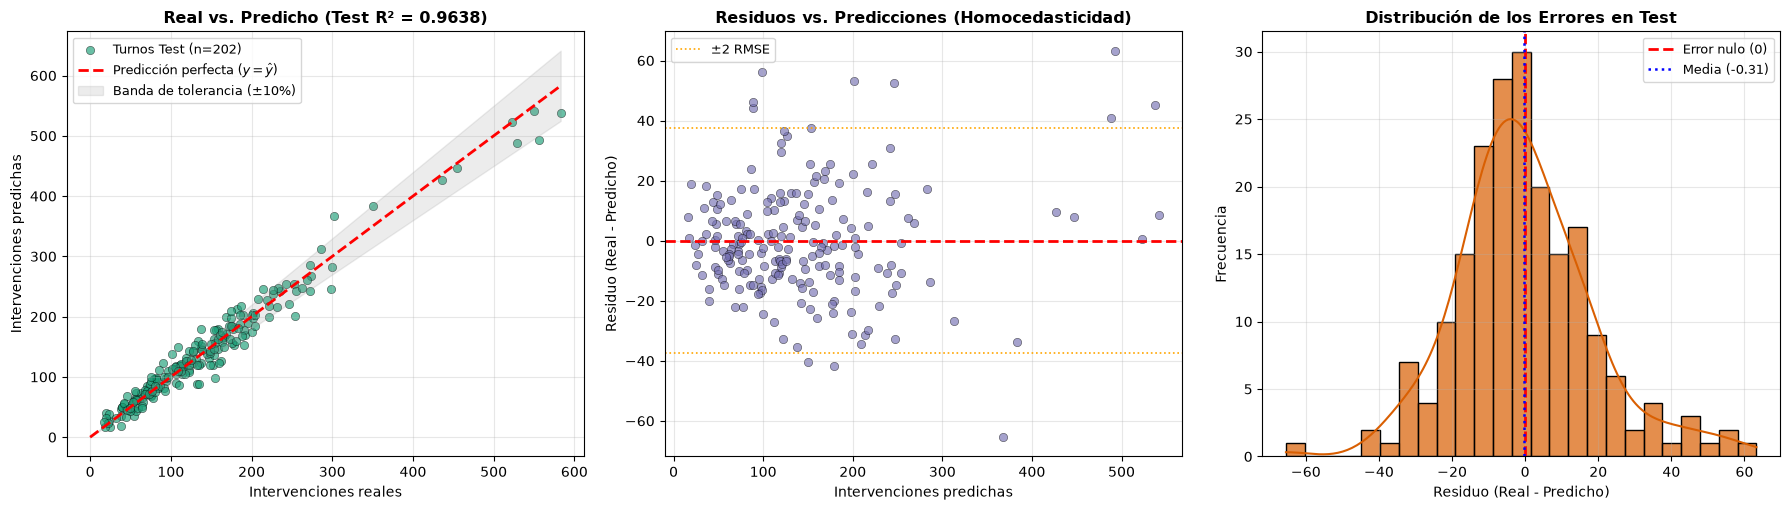

TOP 5 TURNOS CON MAYOR DESVIACIÓN ABSOLUTA EN TEST:


,Distrito,Real,Predicho,Residuo,Error_Abs
46,CENTRO,302,367.4,-65.4,65.4
139,CENTRO,556,492.7,63.3,63.3
35,CHAMBERI,155,98.7,56.3,56.3
164,BARAJAS,254,200.8,53.2,53.2
41,PUENTE DE VALLECAS,299,246.3,52.7,52.7


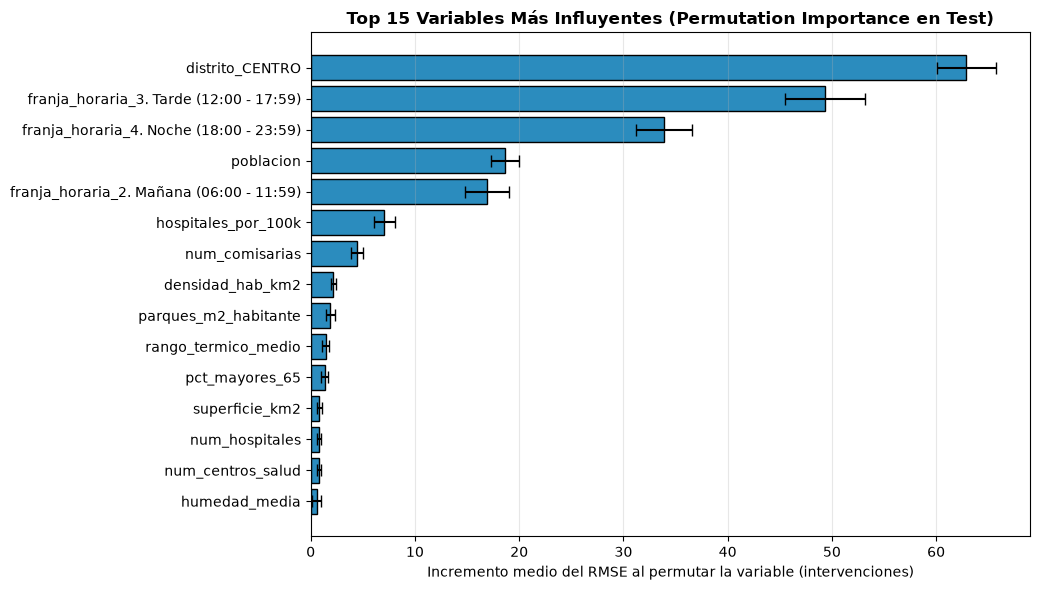

In [19]:
# 1. Cálculo de residuos sobre Test
residuos = y_test - y_pred_final

fig, axes = plt.subplots(1, 3, figsize=(18, 5.2))

# Panel 1: Real vs Predicho con banda operativa del +-10%
axes[0].scatter(y_test, y_pred_final, alpha=0.65, color='#1b9e77', edgecolors='k', linewidth=0.4, label='Turnos Test (n=202)')
max_val = max(y_test.max(), y_pred_final.max())
x_diag = np.linspace(0, max_val, 100)
axes[0].plot(x_diag, x_diag, 'r--', linewidth=2, label='Predicción perfecta ($y = \\hat{y}$)')
axes[0].fill_between(x_diag, x_diag * 0.90, x_diag * 1.10, color='gray', alpha=0.15, label='Banda de tolerancia (±10%)')
axes[0].set_title(f'Real vs. Predicho (Test R² = {test_r2_final:.4f})', fontsize=11.5, fontweight='bold')
axes[0].set_xlabel('Intervenciones reales')
axes[0].set_ylabel('Intervenciones predichas')
axes[0].legend(loc='upper left', fontsize=9)
axes[0].grid(alpha=0.3)

# Panel 2: Residuos vs Valores Predichos (Diagnóstico de sesgo y heterocedasticidad)
axes[1].scatter(y_pred_final, residuos, alpha=0.65, color='#7570b3', edgecolors='k', linewidth=0.4)
axes[1].axhline(0, color='r', linestyle='--', linewidth=2)
axes[1].axhline(2 * test_rmse_final, color='orange', linestyle=':', linewidth=1.2, label='±2 RMSE')
axes[1].axhline(-2 * test_rmse_final, color='orange', linestyle=':', linewidth=1.2)
axes[1].set_title('Residuos vs. Predicciones (Homocedasticidad)', fontsize=11.5, fontweight='bold')
axes[1].set_xlabel('Intervenciones predichas')
axes[1].set_ylabel('Residuo (Real - Predicho)')
axes[1].legend(loc='upper left', fontsize=9)
axes[1].grid(alpha=0.3)

# Panel 3: Distribución de los Residuos
sns.histplot(residuos, kde=True, ax=axes[2], color='#d95f02', bins=25, edgecolor='black', alpha=0.7)
axes[2].axvline(0, color='r', linestyle='--', linewidth=2, label='Error nulo (0)')
axes[2].axvline(residuos.mean(), color='blue', linestyle=':', linewidth=1.8, label=f'Media ({residuos.mean():.2f})')
axes[2].set_title('Distribución de los Errores en Test', fontsize=11.5, fontweight='bold')
axes[2].set_xlabel('Residuo (Real - Predicho)')
axes[2].set_ylabel('Frecuencia')
axes[2].legend(fontsize=9)
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.show()

# 2. Auditoría de los 5 turnos con mayor error absoluto en Test
df_errores = X_test.copy()
df_errores['Real'] = y_test.values
df_errores['Predicho'] = np.round(y_pred_final, 1)
df_errores['Residuo'] = np.round(residuos.values, 1)
df_errores['Error_Abs'] = np.abs(df_errores['Residuo'])

# Reconstruir etiquetas legibles de distrito y turno si están en one-hot encoding
cols_distrito = [c for c in X_test.columns if c.startswith('distrito_')]
cols_turno = [c for c in X_test.columns if c.startswith('turno_')]

cols_mostrar = ['Real', 'Predicho', 'Residuo', 'Error_Abs']
if 'mes' in df_errores.columns:
    cols_mostrar.insert(0, 'mes')
if cols_distrito:
    df_errores['Distrito'] = df_errores[cols_distrito].idxmax(axis=1).str.replace('distrito_', '')
    cols_mostrar.insert(0, 'Distrito')
if cols_turno:
    df_errores['Turno'] = df_errores[cols_turno].idxmax(axis=1).str.replace('turno_', '')
    cols_mostrar.insert(1, 'Turno')

print("TOP 5 TURNOS CON MAYOR DESVIACIÓN ABSOLUTA EN TEST:")
print("=" * 75)
display(df_errores.sort_values('Error_Abs', ascending=False)[cols_mostrar].head(5))

# 3. Importancia de Variables por Permutación (Permutation Importance en Test)
perm_imp = permutation_importance(
    modelo_final, X_test, y_test,
    n_repeats=15,
    scoring='neg_root_mean_squared_error',
    random_state=42,
    n_jobs=-1
)

df_imp = pd.DataFrame({
    'Variable': X_test.columns,
    'Importancia_RMSE': perm_imp.importances_mean,
    'Std': perm_imp.importances_std
}).sort_values('Importancia_RMSE', ascending=False).head(15)

plt.figure(figsize=(10.5, 6))
plt.barh(
    df_imp['Variable'], df_imp['Importancia_RMSE'],
    xerr=df_imp['Std'], color='#2b8cbe', edgecolor='black', capsize=4
)
plt.gca().invert_yaxis()
plt.title('Top 15 Variables Más Influyentes (Permutation Importance en Test)', fontsize=12, fontweight='bold')
plt.xlabel('Incremento medio del RMSE al permutar la variable (intervenciones)')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

### Interpretación del Diagnóstico de Residuos y Factores Clave del Modelo

#### 1. Validación estadística de los residuos (`Test`, $n = 202$)
* **Ausencia de sesgo sistemático:** La distribución de los errores está centrada prácticamente en cero (**media = $-0,31$ intervenciones**) y presenta una forma acampanada y simétrica alrededor del origen, lo que confirma que el `Voting Ponderado (35% RF / 65% HistGB)` no sobreestima ni infraestima de manera sistemática.
* **Estabilidad en todo el rango de demanda:** El diagrama de dispersión **Real vs. Predicho** muestra que la gran mayoría de los turnos se mantienen dentro de la banda operativa del **$\pm 10\%$**, mientras que en el gráfico **Residuos vs. Predicciones** más del 95 % de las observaciones permanecen dentro de los límites de $\pm 2\text{ RMSE}$ ($\pm 37,5$ intervenciones).
* **Auditoría de las desviaciones máximas:** Los 5 mayores residuos absolutos se concentran en distritos con alta volatilidad de población flotante o eventos puntuales: **`CENTRO`** (con dos turnos atípicos de $-65,4$ y $+63,3$ intervenciones, asociados a meses extremos como agosto, donde Madrid se vacia por vacaciones,frente a meses de máxima afluencia turística y navideña), **`CHAMBERÍ`** ($+56,3$), **`BARAJAS`** ($+53,2$, vinculado a picos de tránsito aeroportuario) y **`PUENTE DE VALLECAS`** ($+52,7$).

#### 2. Determinantes de la demanda asistencial (`Permutation Importance`)
El análisis de importancia por permutación sobre `Test` revela una jerarquía operativa muy clara en la generación de emergencias del SAMUR:
1. **El efecto singular del distrito Centro (`distrito_CENTRO`, $\Delta\text{RMSE} \approx +63$):** Es con diferencia el predictor más determinante del modelo. Su condición de núcleo turístico, comercial y de ocio nocturno desacopla su demanda de su población empadronada.
2. **La dinámica circadiana por franjas horarias:** Las franjas de **Tarde (`12:00–17:59`, $\Delta\text{RMSE} \approx +49$)**, **Noche (`18:00–23:59`, $\Delta\text{RMSE} \approx +34$)** y **Mañana (`06:00–11:59`, $\Delta\text{RMSE} \approx +17$)** gobiernan el ritmo diario de activaciones frente a la madrugada, reflejando la movilidad laboral y el ocio vespertino/nocturno.
3. **Estructura demográfica e infraestructuras urbanas:** En el resto de distritos, el volumen basal viene explicado por la **`poblacion`**, la **`densidad_hab_km2`**, el envejecimiento (**`pct_mayores_65`**) y la dotación de equipamientos (**`hospitales_por_100k`**, **`num_comisarias`**, **`parques_m2_habitante`**), que actúan como indicadores de actividad urbana y flujo de personas.
4. **Modulación meteorológica:** Variables como el **`rango_termico_medio`** y la **`humedad_media`** aportan un ajuste fino adicional sobre los cambios estacionales y episodios de estrés térmico.

#### 3. Conclusión y utilidad para la gestión operativa
La combinación de un modelo ensamblado no lineal (`35% Random Forest + 65% HistGradientBoosting`) sobre variables espaciales, temporales, sociodemográficas y meteorológicas permite predecir la demanda mensual por distrito y turno con un **error relativo ponderado ($\text{WAPE}$) del 9,79 %** y un **$R^2$ del 96,38 %** en datos inéditos. Esta herramienta ofrece al servicio de emergencias una base cuantitativa fiable para **dimensionar las guardias y redistribuir unidades móviles preventivas**, reforzando especialmente el distrito Centro y los turnos de tarde y noche sin sobredimensionar los turnos de madrugada.

In [20]:
import joblib

ruta_modelo = os.path.join(carpeta_datos, 'modelo_samur_def.pkl')

# Guardamos el modelo ya entrenado junto con el orden de columnas y metadatos
artefacto_modelo = {
    'modelo': modelo_final,
    'nombre': nombre_final,
    'columnas': list(X_train.columns),
    'metricas_test': {
        'MAE': round(test_mae_final, 2),
        'RMSE': round(test_rmse_final, 2),
        'WAPE': round(test_wape_final, 2),
        'R2': round(test_r2_final, 4)
    }
}

joblib.dump(artefacto_modelo, ruta_modelo)
print(f"Modelo definitivo ('{nombre_final}') guardado correctamente en:\n  {ruta_modelo}")

Modelo definitivo ('Voting Ponderado (35% RF / 65% HistGB)') guardado correctamente en:
  C:\Users\bario\OneDrive\Documentos\UC3M\PROYECTO EN CIENCIA DE DATOS\proyecto_emergencias-20260915T155207Z-1-001\proyecto_emergencias\datasets_modelos\modelo_samur_def.pkl
